In [ ]:
# Run this once/as needed
# !wget https://raw.githubusercontent.com/alexeygrigorev/minsearch/main/minsearch.py

In [ ]:
import pandas as pd

## Ingestion

In [ ]:
df = pd.read_csv('../data/medquad.csv')
df = df[0:1028]
df

In [ ]:
documents = df.to_dict(orient='records')

In [ ]:
documents

In [ ]:
import minsearch

In [ ]:
index = minsearch.Index(
    text_fields=['question','answer','source','focus_area'],
    keyword_fields=['id']
)

In [ ]:
index.fit(documents)

In [ ]:
index

## RAG flow

In [ ]:
from openai import OpenAI

client = OpenAI()

In [ ]:
def search(query):
    boost = {}

    results = index.search(
        query=query,
        filter_dict={},
        boost_dict=boost,
        num_results=10
    )

    return results

In [ ]:
prompt_template = """
You're a medical question answering assistant. Answer the QUESTION based on the CONTEXT from our question and answer database.
Use only the facts from the CONTEXT when answering the QUESTION.

QUESTION: {question}

CONTEXT:
{context}
""".strip()

entry_template = """
question: {question}
answer: {answer}
source: {source}
focus_area: {focus_area}

""".strip()

def build_prompt(query, search_results):
    context = ""
    
    for doc in search_results:
        context = context + entry_template.format(**doc) + "\n\n"

    prompt = prompt_template.format(question=query, context=context).strip()
    return prompt

In [ ]:
def llm(prompt, model='gpt-4o-mini'):
    response = client.chat.completions.create(
        model=model,
        messages=[{"role": "user", "content": prompt}]
    )
    
    return response.choices[0].message.content

In [ ]:
def rag(query, model='gpt-4o-mini'):
    search_results = search(query)
    prompt = build_prompt(query, search_results)
    #print(prompt)
    answer = llm(prompt, model=model)
    return answer

In [ ]:
question = 'Can diabetes be prevented, and if so, how?'
answer = rag(question)
print(answer)

## Retrieval evaluation

In [ ]:
df_question = pd.read_csv('../data/ground-truth-retrieval.csv')

In [ ]:
df_question.head()

In [ ]:
ground_truth = df_question.to_dict(orient='records')

In [ ]:
ground_truth[0]

In [ ]:
def hit_rate(relevance_total):
    cnt = 0

    for line in relevance_total:
        if True in line:
            cnt = cnt + 1

    return cnt / len(relevance_total)

def mrr(relevance_total):
    total_score = 0.0

    for line in relevance_total:
        for rank in range(len(line)):
            if line[rank] == True:
                total_score = total_score + 1 / (rank + 1)

    return total_score / len(relevance_total)

In [ ]:
def minsearch_search(query):
    boost = {}

    results = index.search(
        query=query,
        filter_dict={},
        boost_dict=boost,
        num_results=10
    )

    return results

In [ ]:
def evaluate(ground_truth, search_function):
    relevance_total = []

    for q in tqdm(ground_truth):
        doc_id = q['id']
        results = search_function(q)
        relevance = [d['id'] == doc_id for d in results]
        relevance_total.append(relevance)

    return {
        'hit_rate': hit_rate(relevance_total),
        'mrr': mrr(relevance_total),
    }

In [ ]:
from tqdm.auto import tqdm

In [ ]:
evaluate(ground_truth, lambda q: minsearch_search(q['question']))

## Finding the best parameters

In [ ]:
df_validation = df_question[:100]
df_test = df_question[100:]

In [ ]:
import random

def simple_optimize(param_ranges, objective_function, n_iterations=10):
    best_params = None
    best_score = float('-inf')  # Assuming we're minimizing. Use float('-inf') if maximizing.

    for _ in range(n_iterations):
        # Generate random parameters
        current_params = {}
        for param, (min_val, max_val) in param_ranges.items():
            if isinstance(min_val, int) and isinstance(max_val, int):
                current_params[param] = random.randint(min_val, max_val)
            else:
                current_params[param] = random.uniform(min_val, max_val)
        
        # Evaluate the objective function
        current_score = objective_function(current_params)
        
        # Update best if current is better
        if current_score > best_score:  # Change to > if maximizing
            best_score = current_score
            best_params = current_params
    
    return best_params, best_score

In [ ]:
gt_val = df_validation.to_dict(orient='records')

In [ ]:
def minsearch_search(query, boost=None):
    if boost is None:
        boost = {}

    results = index.search(
        query=query,
        filter_dict={},
        boost_dict=boost,
        num_results=10
    )

    return results

In [ ]:
param_ranges = {
    'question': (0.0, 3.0),
    'answer': (0.0, 3.0),
    'source': (0.0, 3.0),
    'focus_area': (0.0, 3.0),
}

def objective(boost_params):
    def search_function(q):
        return minsearch_search(q['question'], boost_params)

    results = evaluate(gt_val, search_function)
    return results['mrr']

In [ ]:
simple_optimize(param_ranges, objective, n_iterations=20)

In [ ]:
def minsearch_improved(query):
    boost = {
        'question': 0.3417604466420481,
        'answer': 1.8419912735713542,
        'source': 0.25631365201530965,
        'focus_area': 0.22228140744464786
    }

    results = index.search(
        query=query,
        filter_dict={},
        boost_dict=boost,
        num_results=10
    )

    return results

evaluate(ground_truth, lambda q: minsearch_improved(q['question']))

## 檢索內容評估：Context Precision 與 Context Recall（Ragas）



In [ ]:
# 第一格：確認目前的 Notebook 能載入 Ragas 評估工具

# ── 1. 查看這份 Notebook 使用哪一個 Python ──

# sys 是 Python 內建模組，可以取得目前執行環境的資訊。
import sys

# sys.executable 是目前 Jupyter 核心使用的 Python 執行檔路徑。
# 你的電腦同時有 Python 3.11 和 3.13，因此這行能幫你確認：
# 如果稍後出現「找不到套件」，該檢查的是哪一個 Python 環境。
print("目前的 Python：", sys.executable)


# ── 2. 查看目前環境安裝的套件版本 ──

# version 是 Python 提供的查詢函式。
# 把套件名稱傳給它，例如 version("ragas")，就能取得已安裝的版本號。
from importlib.metadata import version

# pyarrow 是後續載入資料處理元件時會用到的套件。
# 這一行先確認目前的 Python 找得到它，並印出版本。
print("pyarrow 版本：", version("pyarrow"))

# ragas 是這次用來計算 Context Precision 和 Context Recall 的評估套件。
# 你的程式使用 Ragas 0.4.4 的寫法，印出版本方便之後核對。
print("ragas 版本：", version("ragas"))


# ── 3. 確認 pyarrow.dataset 實際載入成功 ──

# 上一步查的是「安裝紀錄」；這一步才真的載入 pyarrow.dataset 元件。
# 你之前遇過 DLL load failed：即使查得到版本，載入時仍可能失敗。
# 如果這行出錯，Notebook 會顯示錯誤，並停止執行這個儲存格後面的程式。
import pyarrow.dataset

# Python 能執行到這一行，就表示上一行的 import 已成功。
print("① pyarrow.dataset 載入成功")


# ── 4. 載入本次要用的兩個 Ragas 官方指標 ──

# from ... import ... 的意思是：從指定模組載入後面列出的名稱。
#
# ContextPrecision：之後用來評估，對得到標準答案有用的文件是否排在前面。
# ContextRecall：之後用來評估，找回的文件合計能支持多少標準答案中的陳述。
#
# 這裡只把兩個指標類別載入，讓後續儲存格能使用它們。
# 真正送出題目和文件、請評審模型判讀，是後面呼叫 .ascore(...) 時才發生。
from ragas.metrics.collections import ContextPrecision, ContextRecall

print("② Ragas 指標載入成功")

目前的 Python： C:\Users\yweiw\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe
pyarrow 版本： 26.0.1
ragas 版本： 0.4.4
① pyarrow.dataset 載入成功


C:\Users\yweiw\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


② Ragas 指標載入成功


In [ ]:
# 第二格：讀取資料，準備第 1738 題的 Ragas 評估輸入

from pathlib import Path
import pandas as pd


# ── 1. 指定專案資料夾 ──

# Path.home() 會取得目前 Windows 使用者的家目錄，例如 C:\Users\yweiw。
# 這裡的 / 是 pathlib 拼接路徑的寫法。
# 後面讀取 CSV 時，都從同一個 project 資料夾出發。
project = Path.home() / "OneDrive/Desktop/PY/medicalQuAD-main/medicalQuAD-main"


# ── 2. 讀取測試題庫 ──

# ground-truth-retrieval.csv 有兩個重要欄位：
#   question：這次拿來測試檢索器的問句。
#   id：這道測試題對應到哪一筆 MedQuAD 來源文件。
#
# pd.read_csv(...) 會把 CSV 讀成一張 pandas 表格（DataFrame）。
# dtype={"id": str} 讓文件 ID 以文字保存，例如 "347"。
# 後面讀取排名檔時，拆出來的 ID 也是文字，兩邊型別一致才方便查找。
# keep_default_na=False 則讓空白文字保留為空字串。
questions = pd.read_csv(
    project / "data/ground-truth-retrieval.csv",
    dtype={"id": str},
    keep_default_na=False,
)


# ── 3. 讀取 MedQuAD 文件庫 ──

# 這次只需要兩個欄位：
#   id：文件編號，用來查找文件。
#   answer：該筆 MedQuAD 紀錄的答案原文。
#
# nrows=1028 是因為這次存下來的 Top 5 排名，
# 當初是在 MedQuAD 的前 1,028 筆文件中檢索得到的。
documents = pd.read_csv(
    project / "data/medquad.csv",
    usecols=["id", "answer"],
    dtype={"id": str},
    keep_default_na=False,
    nrows=1028,
)

# 把 id 設成表格索引。之後就能用文件 ID 直接查出答案原文。
# 例如 documents.at["347", "answer"] 就是「取出文件 347 的 answer」。
# verify_integrity=True 會檢查是否有重複 ID，以免同一個 ID 對到多筆文件。
documents = documents.set_index("id", verify_integrity=True)


# ── 4. 讀取之前已經存好的檢索排名 ──

# context_top5_seed42.csv 記錄每個檢索方法針對每一題找回的前五篇文件。
# 例如 top5_ids 欄位的一格會是這樣的文字："347,339,353,337,342"。
# 這裡直接讀取既有結果，所以不用重新執行 MedCPT。
rankings = pd.read_csv(
    project / "notebooks/context_top5_seed42.csv",
    dtype={"top5_ids": str},
    keep_default_na=False,
)

# 同一題會有不同檢索方法的結果，因此要用兩個欄位一起定位：
#   test_row：哪一道測試題。
#   method：哪一種檢索方法。
# 兩者合起來，才唯一對應到一份 Top 5 排名。
rankings = rankings.set_index(["test_row", "method"], verify_integrity=True)


# ── 5. 選擇一題，取出它的測試問句與檢索排名 ──

test_row = 1738
method = "MedCPT + FAISS"

# .iloc[...] 依照「列的位置」取資料，從 0 開始計算。
# 所以 1738 代表測試題庫中位置為 1738 的那一列。
# test 現在包含這一題的 question 和來源文件 id。
test = questions.iloc[test_row]

# .loc[...] 依照「索引值」查資料。
# 這裡用剛才建立的雙欄索引，查出第 1738 題在 MedCPT 下的排名紀錄。
saved = rankings.loc[(test_row, method)]

# 核對兩份 CSV 的問句是否一致。
# 如果日後有人重新排列題庫，位置 1738 就有可能變成另一道題；
# 這個檢查可以避免把甲題的標準答案配到乙題的檢索結果。
if saved["question"] != test["question"]:
    raise ValueError("問句與排名檔不一致，請檢查資料版本。")


# ── 6. 分清楚「標準答案來源 ID」和「檢索器找回的五個 ID」──

# source_id 來自測試題庫，指向這題原本配對的參考答案。
# 第 1738 題的 source_id 是 "347"。
source_id = test["id"]

# top5_ids 來自檢索排名檔，代表 MedCPT 實際找回了哪些文件。
# .split(",") 把原本的一串文字依逗號拆開。
# .strip() 去除每個 ID 前後可能出現的空白，保留原本的排名順序。
top5_ids = [item.strip() for item in saved["top5_ids"].split(",")]

# 檢查是否剛好有五個不同且非空白的 ID。
# set(...) 會去除重複值，所以長度小於 5 就代表有重複。
if len(top5_ids) != 5 or len(set(top5_ids)) != 5 or "" in top5_ids:
    raise ValueError(f"預期有五個不同且非空白的文件 ID，實際讀到 {top5_ids}")


# ── 7. 把文件 ID 換成文件文字，整理成 Ragas 使用的三個欄位 ──

inputs = {
    # user_input：測試問句。這題問的是染劑在檢查中有什麼用途。
    "user_input": test["question"],

    # reference：透過題庫提供的來源 ID，取出一份完整的原始標準答案。
    # .at[列索引, 欄位名稱] 會取出單一儲存格的值。
    "reference": documents.at[source_id, "answer"],

    # retrieved_contexts：依 MedCPT 的排名，把五個 ID 換成五段文件文字。
    # .loc[top5_ids, "answer"] 按照 top5_ids 的順序取出五筆 answer。
    # .tolist() 把它們轉成 Python 清單，交給 Ragas 使用。
    # 這裡要保留順序，因為 Context Precision 會考慮有用文件排在第幾名。
    "retrieved_contexts": documents.loc[top5_ids, "answer"].tolist(),
}


# ── 8. 印出核對資訊 ──

print("測試問句：", inputs["user_input"])
print("標準答案來源 ID：", source_id)
print("MedCPT 前五篇 ID（依排名）：", top5_ids)
print("準備好的檢索文件篇數：", len(inputs["retrieved_contexts"]))

測試問句： What role does the special dye play in the Diabetic Retinopathy test?
標準答案來源 ID： 347
MedCPT 前五篇 ID（依排名）： ['347', '339', '353', '337', '342']


C:\Users\yweiw\AppData\Local\Temp\ipykernel_30036\994123026.py:20: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  ).set_index("id", verify_integrity=True)
C:\Users\yweiw\AppData\Local\Temp\ipykernel_30036\994123026.py:26: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  ).set_index(["test_row", "method"], verify_integrity=True)


In [ ]:
%pip install httpx

In [ ]:
%pip install "ragas==0.4.4"

In [3]:
import asyncio
import httpx

# 【Ragas 官方】自訂評審使用的介面
from ragas.llms.base import InstructorBaseRagasLLM

JUDGE_MODEL = "gpt-oss:20b"


# 【專題自訂】把 Ragas 的評分提示送給本機 GPT-OSS
class OllamaJudge(InstructorBaseRagasLLM):
    async def agenerate(self, prompt, response_model):
        async with httpx.AsyncClient(timeout=360, trust_env=False) as client:
            response = await client.post(
                "http://localhost:11434/api/chat",
                json={
                    "model": JUDGE_MODEL,
                    "messages": [{"role": "user", "content": prompt}],
                    "stream": False,
                    "think": "low",
                    "format": response_model.model_json_schema(),
                    "options": {
                        "temperature": 0,
                        "num_ctx": 16384,
                        "num_predict": 4096,
                    },
                },
            )

        response.raise_for_status()
        data = response.json()

        if data.get("done_reason") == "length":
            raise RuntimeError(f"{JUDGE_MODEL} 回覆達到長度上限，本次未取得有效分數。")

        return response_model.model_validate_json(data["message"]["content"])

    def generate(self, prompt, response_model):
        return asyncio.run(self.agenerate(prompt, response_model))


judge = OllamaJudge()
print("已設定評審模型：", JUDGE_MODEL)

已設定評審模型： gpt-oss:20b


In [4]:
# 【Ragas 官方】直接匯入官方實作。
from ragas.metrics.collections import ContextPrecision, ContextRecall

# 【專題自訂】指定用本機 GPT-OSS 當評審。
precision_metric = ContextPrecision(llm=judge)
recall_metric = ContextRecall(llm=judge)

In [6]:
# 第 43 格：GPT-OSS 評估 MedCPT + FAISS 的 100 題 Top 5 檢索結果
#
# 執行前，先跑過：
# 1. 資料準備格：建立 project、questions、documents、rankings
# 2. OllamaJudge 那格：建立 JUDGE_MODEL 和 judge
# 3. 指標設定格：建立 precision_metric 和 recall_metric
#
# 【專題自訂】資料配對、保存進度、估計剩餘時間、計算平均。
# 【Ragas 官方】ContextPrecision、ContextRecall 的判定與計分。

from datetime import timedelta
from time import monotonic

import pandas as pd
from IPython.display import display


# 1. 確認評審與結果檔
method = "MedCPT + FAISS"
judge_name = JUDGE_MODEL
n_questions = 100

if judge_name != "gpt-oss:20b":
    raise ValueError(
        f"目前 JUDGE_MODEL 是 {judge_name}，請先執行 GPT-OSS 評審設定格。"
    )

metric_map = {
    "context_precision": precision_metric,
    "context_recall": recall_metric,
}
metric_cols = list(metric_map)

# 防止在 Notebook 換了 judge，卻忘記重新執行建立指標的那一格。
for name, metric in metric_map.items():
    if metric.llm is not judge:
        raise ValueError(
            f"{name} 仍綁定先前的評審。請重新執行建立兩個 Ragas 指標的那一格。"
        )

output = (
    project / "notebooks"
    / "ragas_medcpt_top5_100_seed42_gpt-oss-20b_low.csv"
)

print("評審模型：", judge_name)
print("檢索方法：", method)
print("結果檔案：", output)


# 2. 直接取用已經抽好的 100 題和 MedCPT 排名，不重新抽題。
sample = rankings.xs(method, level="method").sort_index().copy()

if (
    len(sample) != n_questions
    or not sample.index.is_unique
    or sample["question"].nunique() != n_questions
):
    raise ValueError("預期是 100 道不同的 MedCPT 測試題，請檢查排名檔。")

expected = sample[["question", "top5_ids"]].copy()
expected["method"] = method
expected["judge"] = judge_name

source_ids = []

for test_row, saved in sample.iterrows():
    # test_row 是題庫列號；id 是取標準答案用的來源文件 ID。
    test = questions.iloc[test_row]
    source_id = str(test["id"])
    top5_ids = [item.strip() for item in saved["top5_ids"].split(",")]

    if test["question"] != saved["question"]:
        raise ValueError(f"第 {test_row} 題的問句與排名檔不一致。")

    if len(top5_ids) != 5 or len(set(top5_ids)) != 5 or "" in top5_ids:
        raise ValueError(f"第 {test_row} 題的 Top 5 ID 異常：{top5_ids}")

    missing_ids = [
        doc_id for doc_id in [source_id, *top5_ids]
        if doc_id not in documents.index
    ]
    if missing_ids:
        raise ValueError(f"第 {test_row} 題找不到文件 ID：{missing_ids}")

    source_ids.append(source_id)

expected["source_id"] = source_ids


# 3. 讀取 GPT-OSS 自己的進度；第一次執行則建立新表。
if output.exists():
    results = pd.read_csv(
        output,
        dtype={"source_id": str, "top5_ids": str},
        keep_default_na=False,
    ).set_index("test_row", verify_integrity=True)

    if set(results.index) != set(expected.index):
        raise ValueError("舊結果檔的題號與本次 100 題不同。")

    results = results.loc[expected.index].copy()

    for col in expected.columns:
        if col not in results or not results[col].eq(expected[col]).all():
            raise ValueError(f"舊結果檔的 {col} 與本次資料或設定不同。")
else:
    results = expected.copy()

# 分數欄固定為 Float64；0 分是有效結果，空白才需要補跑。
for name in metric_cols:
    if name in results:
        results[name] = pd.to_numeric(
            results[name].replace("", pd.NA),
            errors="raise",
        ).astype("Float64")
    else:
        results[name] = pd.Series(pd.NA, index=results.index, dtype="Float64")

    error_col = f"{name}_error"
    if error_col in results:
        results[error_col] = results[error_col].astype("string").fillna("")
    else:
        results[error_col] = pd.Series("", index=results.index, dtype="string")


def save_results():
    """每評完一個指標就存一次，先寫暫存檔，再取代正式 CSV。"""
    temp = output.with_suffix(".tmp")
    results.to_csv(temp, index_label="test_row", encoding="utf-8-sig")
    temp.replace(output)


# 4. 只評還沒有分數的項目。
total_scores = len(results) * len(metric_cols)
remaining = int(results[metric_cols].isna().sum().sum())

print(f"\n評估題數：{len(results)}")
print(f"已有有效分數：{total_scores - remaining} / {total_scores}")
print(f"本輪待評：{remaining} 個指標\n")

started = monotonic()
attempted = 0

for number, (test_row, saved) in enumerate(expected.iterrows(), start=1):
    pending = [
        name for name in metric_cols
        if pd.isna(results.at[test_row, name])
    ]
    if not pending:
        continue

    top5_ids = [item.strip() for item in saved["top5_ids"].split(",")]

    # 這兩個指標只用問句、標準答案和五篇文件，不需要先生成回答。
    batch_inputs = {
        "user_input": saved["question"],
        "reference": documents.at[saved["source_id"], "answer"],
        "retrieved_contexts": documents.loc[top5_ids, "answer"].tolist(),
    }

    for name in pending:
        print(f"[{number}/{n_questions}] 第 {test_row} 題｜{name}", flush=True)

        try:
            # 【Ragas 官方 API】GPT-OSS 判讀內容，Ragas 計算分數。
            result = await metric_map[name].ascore(**batch_inputs)
            score = float(result.value)

            if not 0 <= score <= 1:
                raise ValueError(f"收到無效分數：{score}")

        except Exception as err:
            # 保留缺值與原因，下一次執行時可重試。
            results.at[test_row, f"{name}_error"] = f"{type(err).__name__}: {err}"
            print(f"  本次未取得分數：{err}", flush=True)

        else:
            results.at[test_row, name] = score
            results.at[test_row, f"{name}_error"] = ""
            print(f"  分數：{score:.4f}", flush=True)

        save_results()

        attempted += 1
        avg_seconds = (monotonic() - started) / attempted
        eta = timedelta(seconds=round(avg_seconds * (remaining - attempted)))
        print(f"  本輪已嘗試 {attempted}/{remaining}，估計剩餘 {eta}", flush=True)


# 5. 彙整結果：兩項都有分數的題目才一起算平均。
scores = results[metric_cols]
complete = scores.dropna()
incomplete = scores.isna().any(axis=1)

print(f"\n兩項皆完成：{len(complete)} / {n_questions} 題")
print(f"有效指標分數：{int(scores.notna().sum().sum())} / {total_scores}")

if not complete.empty:
    display(
        complete.mean()
        .round(4)
        .rename("GPT-OSS 評分平均（兩項皆完成的題目）")
        .to_frame()
    )

if incomplete.any():
    print("以下題目仍缺分數：")
    display(
        results.loc[
            incomplete,
            ["context_precision", "context_precision_error",
             "context_recall", "context_recall_error"],
        ]
    )

print("結果檔：", output)

評審模型： gpt-oss:20b
檢索方法： MedCPT + FAISS
結果檔案： C:\Users\yweiw\OneDrive\Desktop\PY\medicalQuAD-main\medicalQuAD-main\notebooks\ragas_medcpt_top5_100_seed42_gpt-oss-20b_low.csv

評估題數：100
已有有效分數：195 / 200
本輪待評：5 個指標

[27/100] 第 1154 題｜context_precision


C:\Users\yweiw\AppData\Local\Temp\ipykernel_30036\1184721895.py:97: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  ).set_index("test_row", verify_integrity=True)


  分數：0.2000
  本輪已嘗試 1/5，估計剩餘 0:02:07
[40/100] 第 1840 題｜context_precision
  分數：0.8056
  本輪已嘗試 2/5，估計剩餘 0:01:28
[56/100] 第 2524 題｜context_precision
  分數：0.8333
  本輪已嘗試 3/5，估計剩餘 0:00:58
[79/100] 第 3922 題｜context_precision
  分數：0.5000
  本輪已嘗試 4/5，估計剩餘 0:00:29
[84/100] 第 4096 題｜context_recall
  本次未取得分數：gpt-oss:20b 回覆達到長度上限，本次未取得有效分數。
  本輪已嘗試 5/5，估計剩餘 0:00:00

兩項皆完成：99 / 100 題
有效指標分數：199 / 200


,GPT-OSS 評分平均（兩項皆完成的題目）
context_precision,0.7666
context_recall,0.89


以下題目仍缺分數：


,context_precision,context_precision_error,context_recall,context_recall_error
test_row,,,,
4096,0.755556,,<NA>,RuntimeError: gpt-oss:20b 回覆達到長度上限，本次未取得有效分數。


結果檔： C:\Users\yweiw\OneDrive\Desktop\PY\medicalQuAD-main\medicalQuAD-main\notebooks\ragas_medcpt_top5_100_seed42_gpt-oss-20b_low.csv


In [7]:
# 單題重試：第 4096 題｜MedCPT + FAISS｜Ragas Context Recall
#
# 【Ragas 官方】ContextRecall 負責判讀參考答案是否被文件涵蓋並計分。
# 【專題自訂】讀取原始資料、呼叫本機 GPT-OSS、記錄 token 數與重試結果。

import asyncio
import json
import math
from pathlib import Path

import httpx
import pandas as pd

from ragas.llms.base import InstructorBaseRagasLLM
from ragas.metrics.collections import ContextRecall


# ── 1. 這次只重試一題、一個指標 ──

project = Path.home() / "OneDrive/Desktop/PY/medicalQuAD-main/medicalQuAD-main"
notebook_dir = project / "notebooks"

test_row = 4096
method = "MedCPT + FAISS"
judge_model = "gpt-oss:20b"

num_ctx = 32768       # 上下文容量，原本是 16384
num_predict = 8192    # 單次生成上限，原本是 4096

retry_file = notebook_dir / "retry_4096_context_recall_gpt-oss-20b_32k_8k.json"


# ── 2. 從原本的 CSV 取回同一道題、同一份參考答案、同五篇文件 ──

questions = pd.read_csv(
    project / "data/ground-truth-retrieval.csv",
    dtype={"id": str},
    keep_default_na=False,
)

documents = pd.read_csv(
    project / "data/medquad.csv",
    usecols=["id", "answer"],
    dtype={"id": str},
    keep_default_na=False,
    nrows=1028,
).set_index("id", verify_integrity=True)

rankings = pd.read_csv(
    notebook_dir / "context_top5_seed42.csv",
    dtype={"top5_ids": str},
    keep_default_na=False,
).set_index(["test_row", "method"], verify_integrity=True)

test = questions.iloc[test_row]
saved = rankings.loc[(test_row, method)]

if test["question"] != saved["question"]:
    raise ValueError("測試題庫與排名檔的問句不同，請檢查檔案版本。")

source_id = test["id"]
top5_ids = [item.strip() for item in saved["top5_ids"].split(",")]

if len(top5_ids) != 5 or len(set(top5_ids)) != 5 or "" in top5_ids:
    raise ValueError(f"預期有五篇不同的檢索文件，讀到：{top5_ids}")

reference = documents.at[source_id, "answer"]
contexts = documents.loc[top5_ids, "answer"].tolist()

print("測試題號：", test_row)
print("測試問句：", test["question"])
print("標準答案來源 ID：", source_id)
print("前五篇 ID：", top5_ids)
print("標準答案字元數：", len(reference))
print("五篇文件合計字元數：", sum(len(text) for text in contexts))


# ── 3. 把 Ragas 的提示送給 GPT-OSS，記錄 Ollama 的實際回覆狀態 ──

class RecallRetryJudge(InstructorBaseRagasLLM):
    def __init__(self):
        self.calls = []

    async def agenerate(self, prompt, response_model):
        # 32K 上下文在你的筆電上可能比原設定慢，因此放寬等待時間。
        async with httpx.AsyncClient(timeout=900, trust_env=False) as client:
            reply = await client.post(
                "http://localhost:11434/api/chat",
                json={
                    "model": judge_model,
                    "messages": [{"role": "user", "content": prompt}],
                    "stream": False,
                    "think": "low",
                    "format": response_model.model_json_schema(),
                    "options": {
                        "temperature": 0,
                        "num_ctx": num_ctx,
                        "num_predict": num_predict,
                    },
                },
            )

        reply.raise_for_status()
        data = reply.json()
        content = data.get("message", {}).get("content") or ""

        # 這是 Ollama 回報的 token 數，和前面印出的「字元數」不同。
        call = {
            "done_reason": data.get("done_reason"),
            "prompt_eval_count": data.get("prompt_eval_count"),
            "eval_count": data.get("eval_count"),
            "response_chars": len(content),
        }
        self.calls.append(call)

        print(
            f"Ollama 回報｜結束原因：{call['done_reason']}｜"
            f"輸入 token：{call['prompt_eval_count']}｜"
            f"生成 token：{call['eval_count']}｜"
            f"回覆字元：{call['response_chars']}",
            flush=True,
        )

        if call["done_reason"] == "length":
            raise RuntimeError(
                f"仍達到長度上限。請對照上方 token 計數；"
                f"本次設定 num_ctx={num_ctx}、num_predict={num_predict}。"
            )

        if not content.strip():
            raise RuntimeError("GPT-OSS 的回覆內容是空字串，無法取得 Recall 判定。")

        return response_model.model_validate_json(content)

    def generate(self, prompt, response_model):
        return asyncio.run(self.agenerate(prompt, response_model))


# ── 4. 【Ragas 官方 API】只執行 Context Recall ──

retry_judge = RecallRetryJudge()
retry_metric = ContextRecall(llm=retry_judge)

record = {
    "test_row": test_row,
    "method": method,
    "metric": "context_recall",
    "judge": judge_model,
    "think": "low",
    "temperature": 0,
    "num_ctx": num_ctx,
    "num_predict": num_predict,
    "source_id": source_id,
    "top5_ids": top5_ids,
    "context_recall": None,
    "error": None,
}

print(f"\n開始重試第 {test_row} 題的 Context Recall……", flush=True)

try:
    result = await retry_metric.ascore(
        user_input=test["question"],
        reference=reference,
        retrieved_contexts=contexts,
    )

    score = float(result.value)
    if not math.isfinite(score) or not 0 <= score <= 1:
        raise ValueError(f"Ragas 未產生有效分數：{score}")

    record["context_recall"] = score
    print(f"\n成功：第 {test_row} 題的 Context Recall = {score:.4f}")

except Exception as err:
    record["error"] = f"{type(err).__name__}: {err}"
    print(f"\n本次未取得分數：{record['error']}")
    raise

finally:
    # 成功或失敗都留下本次設定與診斷，方便之後寫報告。
    record["ollama_calls"] = retry_judge.calls
    retry_file.write_text(
        json.dumps(record, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    print("單題重試紀錄：", retry_file)

測試題號： 4096
測試問句： How is childhood soft tissue sarcoma diagnosed?
標準答案來源 ID： 819
前五篇 ID： ['819', '823', '824', '826', '822']
標準答案字元數： 16285
五篇文件合計字元數： 53572

開始重試第 4096 題的 Context Recall……


C:\Users\yweiw\AppData\Local\Temp\ipykernel_30036\3370410582.py:47: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  ).set_index("id", verify_integrity=True)
C:\Users\yweiw\AppData\Local\Temp\ipykernel_30036\3370410582.py:53: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  ).set_index(["test_row", "method"], verify_integrity=True)


Ollama 回報｜結束原因：stop｜輸入 token：15979｜生成 token：1777｜回覆字元：6754

成功：第 4096 題的 Context Recall = 1.0000
單題重試紀錄： C:\Users\yweiw\OneDrive\Desktop\PY\medicalQuAD-main\medicalQuAD-main\notebooks\retry_4096_context_recall_gpt-oss-20b_32k_8k.json


In [8]:
import json
import math
from pathlib import Path

import pandas as pd

folder = Path.home() / "OneDrive/Desktop/PY/medicalQuAD-main/medicalQuAD-main/notebooks"
csv_path = folder / "ragas_medcpt_top5_100_seed42_gpt-oss-20b_low.csv"
json_path = folder / "retry_4096_context_recall_gpt-oss-20b_32k_8k.json"

# 1. 讀取批次結果與單題重試紀錄。
#    全部先當文字讀，保留其他題目的分數精度和空白欄位。
df = pd.read_csv(csv_path, dtype=str, keep_default_na=False)
retry = json.loads(json_path.read_text(encoding="utf-8"))

# 2. 確認 JSON 是成功的第 4096 題 Recall 重試。
if (
    str(retry["test_row"]) != "4096"
    or retry["metric"] != "context_recall"
    or retry["judge"] != "gpt-oss:20b"
    or retry["method"] != "MedCPT + FAISS"
    or retry.get("error")
):
    raise ValueError("重試紀錄與預期不符，沒有修改 CSV。")

score = float(retry["context_recall"])
if not math.isfinite(score) or not 0 <= score <= 1:
    raise ValueError(f"重試分數無效：{score}")

# 3. 在 CSV 找到唯一對應的那一列，再核對來源與文件順序。
match = (
    df["test_row"].eq(str(retry["test_row"]))
    & df["method"].eq(retry["method"])
    & df["judge"].eq(retry["judge"])
)
if match.sum() != 1:
    raise ValueError(f"預期找到一列，實際找到 {match.sum()} 列，沒有修改 CSV。")

i = df.index[match][0]
csv_ids = [item.strip() for item in df.at[i, "top5_ids"].split(",")]

if df.at[i, "source_id"] != str(retry["source_id"]) or csv_ids != retry["top5_ids"]:
    raise ValueError("來源 ID 或 Top 5 順序不同，沒有修改 CSV。")

# 如果已合併過相同分數，可以再次執行；遇到不同分數就停止。
old_score = df.at[i, "context_recall"].strip()
if old_score and not math.isclose(float(old_score), score):
    raise ValueError(f"CSV 已有不同分數 {old_score}，沒有覆蓋。")

# 4. 補上 Recall，清除這一項的舊錯誤，記錄重試設定。
df.at[i, "context_recall"] = str(score)
df.at[i, "context_recall_error"] = ""

note_col = "context_recall_retry_note"
if note_col not in df.columns:
    df[note_col] = ""

df.at[i, note_col] = (
    f"單題重試成功；num_ctx={retry['num_ctx']}，"
    f"num_predict={retry['num_predict']}；紀錄檔={json_path.name}"
)

# 先寫暫存檔，寫完才替換原 CSV。
temp = csv_path.with_suffix(".merge.tmp")
df.to_csv(temp, index=False, encoding="utf-8-sig")
temp.replace(csv_path)

# 5. 顯示合併結果，以及目前真正剩下的缺分。
metrics = df[["context_precision", "context_recall"]].apply(pd.to_numeric)
missing = metrics.isna().any(axis=1)

print(f"第 4096 題合併完成，Context Recall = {score:.4f}")
print(f"有效分數：{metrics.notna().sum().sum()} / {metrics.size}")
print(f"兩項皆完成：{(~missing).sum()} / {len(df)} 題")

if missing.any():
    print("\n仍缺分的題目：")
    display(df.loc[missing, ["test_row", "context_precision", "context_recall"]])

第 4096 題合併完成，Context Recall = 1.0000
有效分數：200 / 200
兩項皆完成：100 / 100 題


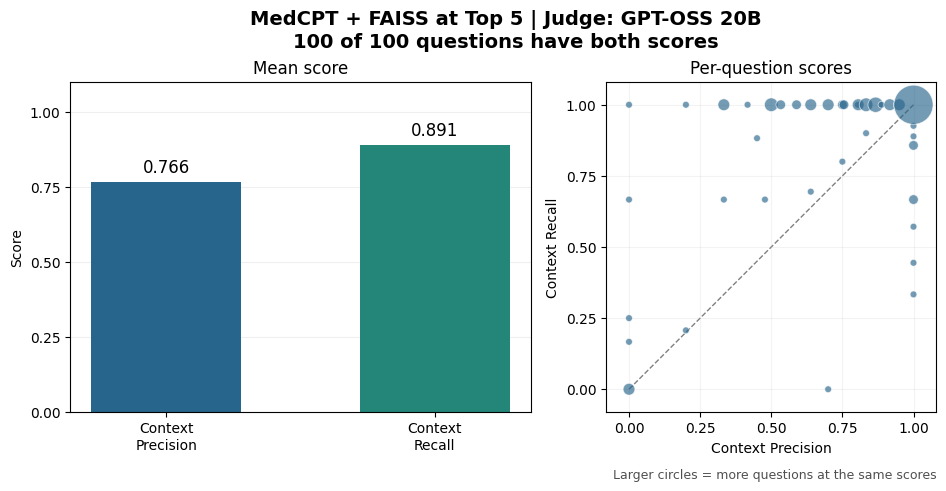

兩項皆完成：100 / 100 題
平均 Context Precision：0.7665
平均 Context Recall：0.8911
圖檔位置： C:\Users\yweiw\OneDrive\Desktop\PY\medicalQuAD-main\medicalQuAD-main\notebooks\ragas_medcpt_top5_100_seed42_gpt-oss-20b_low.png

Precision 與 Recall 落差最大的 5 題：


,context_precision,context_recall,分數差距
test_row,,,
1045,0.0000,1.0,1.0000
2054,0.2000,1.0,0.8000
1029,0.7000,0.0,0.7000
79,0.3333,1.0,0.6667
879,0.3333,1.0,0.6667


In [9]:
# 畫圖：MedCPT Top 5 的 Ragas Context Precision 與 Context Recall
# 資料來源：由 GPT-OSS 評分的 100 題批次結果 CSV

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# 1. 讀取合併後的結果檔
folder = Path.home() / "OneDrive/Desktop/PY/medicalQuAD-main/medicalQuAD-main/notebooks"
csv_path = folder / "ragas_medcpt_top5_100_seed42_gpt-oss-20b_low.csv"
image_path = csv_path.with_suffix(".png")

df = pd.read_csv(csv_path)

# 確認沒有把其他檢索方法、評審或重複題目混進來。
if (
    len(df) != 100
    or df["test_row"].nunique() != 100
    or not df["method"].eq("MedCPT + FAISS").all()
    or not df["judge"].eq("gpt-oss:20b").all()
):
    raise ValueError("資料與預期不符，請確認是 GPT-OSS 評 MedCPT 的 100 題結果檔。")

# 2. 分數空白代表未取得有效結果，不能當作 0 分。
cols = ["context_precision", "context_recall"]
scores = df.set_index("test_row")[cols].apply(pd.to_numeric, errors="raise")
complete = scores.dropna().copy()

if complete.empty:
    raise ValueError("目前沒有兩項分數都完成的題目。")
if not complete.ge(0).all().all() or not complete.le(1).all().all():
    raise ValueError("資料中有不在 0～1 範圍內的分數。")

means = complete.mean()

# Ragas 有時會產生 0.99999999995 這類浮點數。
# 只在畫散點時四捨五入，讓相同位置的題目可以合併計數。
# 左圖的平均仍使用原始分數。
points = (
    complete.round(6)
    .groupby(cols)
    .size()
    .reset_index(name="count")
)

# 3. 建立左右兩張子圖
fig, (ax_mean, ax_item) = plt.subplots(
    1, 2, figsize=(10, 4.8), constrained_layout=True
)
fig.suptitle(
    f"MedCPT + FAISS at Top 5 | Judge: GPT-OSS 20B\n"
    f"{len(complete)} of {len(scores)} questions have both scores",
    fontsize=14,
    fontweight="bold",
)

# 左圖：在同一批完整題目上比較平均分數
bars = ax_mean.bar(
    ["Context\nPrecision", "Context\nRecall"],
    means.to_numpy(),
    color=["#28658C", "#248579"],
    width=0.56,
)
ax_mean.bar_label(bars, fmt="%.3f", padding=4, fontsize=12)
ax_mean.set_title("Mean score")
ax_mean.set_ylabel("Score")
ax_mean.set_ylim(0, 1.10)
ax_mean.set_yticks([0, 0.25, 0.50, 0.75, 1.00])
ax_mean.grid(axis="y", alpha=0.2)
ax_mean.set_axisbelow(True)

# 右圖：橫軸是 Precision，縱軸是 Recall
ax_item.plot([0, 1], [0, 1], "--", color="gray", linewidth=1, zorder=1)
ax_item.scatter(
    points["context_precision"],
    points["context_recall"],
    s=24 * points["count"],       # 圓點面積與該位置的題數成正比
    color="#28658C",
    alpha=0.65,
    edgecolors="white",
    linewidths=0.6,
    zorder=2,
)
ax_item.set_title("Per-question scores")
ax_item.set_xlabel("Context Precision")
ax_item.set_ylabel("Context Recall")
ax_item.set_xlim(-0.08, 1.08)
ax_item.set_ylim(-0.08, 1.08)
ax_item.set_aspect("equal")
ax_item.set_xticks([0, 0.25, 0.50, 0.75, 1.00])
ax_item.set_yticks([0, 0.25, 0.50, 0.75, 1.00])
ax_item.grid(alpha=0.15)
ax_item.text(
    0.02, -0.20, "Larger circles = more questions at the same scores",
    transform=ax_item.transAxes, fontsize=9, color="#505050",
)

# 4. 儲存 PNG，並在 Notebook 顯示
fig.savefig(image_path, dpi=220, bbox_inches="tight")
plt.show()

print(f"兩項皆完成：{len(complete)} / {len(scores)} 題")
print(f"平均 Context Precision：{means['context_precision']:.4f}")
print(f"平均 Context Recall：{means['context_recall']:.4f}")
print("圖檔位置：", image_path)

# 列出兩個指標落差最大的 5 題，方便從圖回頭查原文。
review = complete.copy()
review["分數差距"] = (
    review["context_precision"] - review["context_recall"]
).abs()

print("\nPrecision 與 Recall 落差最大的 5 題：")
display(review.nlargest(5, "分數差距").round(4))

In [11]:
# 【專題自訂】生成回答。本格不計算 Faithfulness。
# 三個模型共用問句、Top 5 文件、文件順序及作答指令。
# 每生成一份回答就存檔。已完成的回答不重新生成。

import json
import os
from pathlib import Path

import httpx
import pandas as pd

project = Path.home() / "OneDrive/Desktop/PY/medicalQuAD-main/medicalQuAD-main"
nb_dir = project / "notebooks"
answer_file = nb_dir / "faithfulness_answers_3models_medcpt_100_seed42.jsonl"

answer_models = [
    "qwen35-ragas-16k",
    "gemma4:e4b-it-q4_K_M",
    "llama3.1:8b",
]

system_prompt = (
    "Answer the medical question in English using only the supplied passages. "
    "Answer what was asked and be concise. If the passages do not provide "
    "enough information, say what cannot be determined from them."
)

# 1. 取出固定的 100 道 MedCPT 題目，不重新抽題或檢索。
ranks = pd.read_csv(
    nb_dir / "context_top5_seed42.csv",
    dtype={"top5_ids": str},
    keep_default_na=False,
)
sample = (
    ranks.loc[ranks["method"].eq("MedCPT + FAISS")]
    .set_index("test_row", verify_integrity=True)
    .sort_index()
)
if len(sample) != 100 or sample["question"].nunique() != 100:
    raise ValueError("預期為 100 道不同的 MedCPT 測試題。")

docs = pd.read_csv(
    project / "data/medquad.csv",
    usecols=["id", "answer"],
    dtype={"id": str},
    keep_default_na=False,
    nrows=1028,
).set_index("id", verify_integrity=True)

# 每題只準備一次文件，三個模型共用同一份內容。
cases = {}
for test_row, row in sample.iterrows():
    ids = [item.strip() for item in row["top5_ids"].split(",")]
    if len(ids) != 5 or len(set(ids)) != 5 or "" in ids:
        raise ValueError(f"第 {test_row} 題的 Top 5 ID 異常：{ids}")

    contexts = docs.loc[ids, "answer"].tolist()
    if not all(isinstance(x, str) and x.strip() for x in contexts):
        raise ValueError(f"第 {test_row} 題有空白文件。")

    cases[int(test_row)] = {
        "user_input": row["question"],
        "top5_ids": ids,
        "retrieved_contexts": contexts,
    }

# 2. 讀回已存的回答，以「回答模型＋題號」識別每筆。
answers = {}
if answer_file.exists():
    with answer_file.open(encoding="utf-8") as f:
        for line in f:
            record = json.loads(line)
            key = (record["answer_model"], record["test_row"])
            if key in answers:
                raise ValueError(f"回答檔有重複紀錄：{key}")
            answers[key] = record


def save_answers():
    # 先寫完整暫存檔，再替換正式檔，避免中斷時留下半行 JSON。
    temp = answer_file.with_suffix(".tmp")
    with temp.open("w", encoding="utf-8") as f:
        for record in answers.values():
            f.write(json.dumps(record, ensure_ascii=False) + "\n")
    os.replace(temp, answer_file)


# 這些設定也記入結果檔，續跑時一併核對。
generation_options = {"temperature": 0, "num_ctx": 16384, "num_predict": 1024}

# 3. 逐個模型生成回答。不傳入 MedQuAD 標準答案。
async with httpx.AsyncClient(timeout=360, trust_env=False) as client:
    for model in answer_models:
        for number, (test_row, case) in enumerate(cases.items(), start=1):
            key = (model, test_row)
            expected = {
                "test_row": test_row,
                "method": "MedCPT + FAISS",
                "answer_model": model,
                "system_prompt": system_prompt,
                "generation_options": generation_options,
                **case,
            }

            if key in answers:
                previous = answers[key]
                if any(previous.get(k) != v for k, v in expected.items()):
                    raise ValueError(f"{key} 的輸入或設定已改變，請使用新的輸出檔。")
                if previous.get("response", "").strip():
                    continue

            passages = "\n\n".join(
                f"Passage {i}:\n{text}"
                for i, text in enumerate(case["retrieved_contexts"], start=1)
            )

            print(f"[{number}/100] {model}｜第 {test_row} 題｜生成回答", flush=True)

            payload = {
                "model": model,
                "stream": False,
                "messages": [
                    {"role": "system", "content": system_prompt},
                    {
                        "role": "user",
                        "content": (
                            f"Question:\n{case['user_input']}\n\nPassages:\n{passages}"
                        ),
                    },
                ],
                "options": generation_options,
            }
            # 沿用你先前的 Qwen 設定。對其他型號使用其預設推理模式。
            if model == "qwen35-ragas-16k":
                payload["think"] = False

            try:
                reply = await client.post("http://localhost:11434/api/chat", json=payload)
                reply.raise_for_status()
                data = reply.json()
                response = data["message"]["content"].strip()

                if data.get("done_reason") == "length":
                    answers[key] = {
                        **expected,
                        "response": "",  # 留空，避免之後把截斷的回答拿去評 Faithfulness
                        "error": (
                            f"生成達到長度上限；"
                            f"輸入 token={data.get('prompt_eval_count')}，"
                            f"生成 token={data.get('eval_count')}"
                        ),
                    }
                    save_answers()
                    print(f"  {model}｜第 {test_row} 題達到長度上限，已記錄，繼續下一題。", flush=True)
                    continue
                if not response:
                    raise ValueError("模型回傳空白回答。")

            except Exception as err:
                answers[key] = {**expected, "response": "", "error": str(err)}
                save_answers()
                raise  # 停在實際錯誤處；修正後重跑本格可續跑。

            answers[key] = {**expected, "response": response, "error": ""}
            save_answers()

for model in answer_models:
    count = sum(bool(answers.get((model, t), {}).get("response")) for t in cases)
    print(f"{model}：{count}/100 份回答")
print("回答檔：", answer_file)

C:\Users\yweiw\AppData\Local\Temp\ipykernel_30036\4035672535.py:36: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  .set_index("test_row", verify_integrity=True)
C:\Users\yweiw\AppData\Local\Temp\ipykernel_30036\4035672535.py:48: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  ).set_index("id", verify_integrity=True)


[29/100] gemma4:e4b-it-q4_K_M｜第 1277 題｜生成回答
  gemma4:e4b-it-q4_K_M｜第 1277 題達到長度上限，已記錄，繼續下一題。
[30/100] gemma4:e4b-it-q4_K_M｜第 1388 題｜生成回答
[31/100] gemma4:e4b-it-q4_K_M｜第 1418 題｜生成回答
[32/100] gemma4:e4b-it-q4_K_M｜第 1430 題｜生成回答
[33/100] gemma4:e4b-it-q4_K_M｜第 1583 題｜生成回答
[34/100] gemma4:e4b-it-q4_K_M｜第 1619 題｜生成回答
[35/100] gemma4:e4b-it-q4_K_M｜第 1726 題｜生成回答
[36/100] gemma4:e4b-it-q4_K_M｜第 1729 題｜生成回答
[37/100] gemma4:e4b-it-q4_K_M｜第 1738 題｜生成回答
[38/100] gemma4:e4b-it-q4_K_M｜第 1760 題｜生成回答
[39/100] gemma4:e4b-it-q4_K_M｜第 1789 題｜生成回答
[40/100] gemma4:e4b-it-q4_K_M｜第 1840 題｜生成回答
[41/100] gemma4:e4b-it-q4_K_M｜第 1867 題｜生成回答
[42/100] gemma4:e4b-it-q4_K_M｜第 1878 題｜生成回答
[43/100] gemma4:e4b-it-q4_K_M｜第 1927 題｜生成回答
[44/100] gemma4:e4b-it-q4_K_M｜第 1951 題｜生成回答
[45/100] gemma4:e4b-it-q4_K_M｜第 2054 題｜生成回答
[46/100] gemma4:e4b-it-q4_K_M｜第 2177 題｜生成回答
[47/100] gemma4:e4b-it-q4_K_M｜第 2233 題｜生成回答
[48/100] gemma4:e4b-it-q4_K_M｜第 2253 題｜生成回答
[49/100] gemma4:e4b-it-q4_K_M｜第 2296 題｜生成回答
[50/100] gemma4:e4b-it-q4_K

In [12]:
# 第 44 格的補跑：只處理 Gemma 第 1277、2458 題。
# 先確認第 44 格已經跑完，避免兩格同時寫入同一份回答檔。

import json
from pathlib import Path

import httpx

folder = Path.home() / "OneDrive/Desktop/PY/medicalQuAD-main/medicalQuAD-main/notebooks"
answer_file = folder / "faithfulness_answers_3models_medcpt_100_seed42.jsonl"
model = "gemma4:e4b-it-q4_K_M"

with answer_file.open(encoding="utf-8") as f:
    records = [json.loads(line) for line in f if line.strip()]

targets = [
    r for r in records
    if r["answer_model"] == model and r["test_row"] in (1277, 2458)
]
if sorted(r["test_row"] for r in targets) != [1277, 2458]:
    raise ValueError("找不到預期的兩筆 Gemma 紀錄，請確認回答檔。")


def save_progress():
    temp = answer_file.with_suffix(".tmp")
    with temp.open("w", encoding="utf-8") as f:
        for record in records:
            f.write(json.dumps(record, ensure_ascii=False) + "\n")
    temp.replace(answer_file)


async with httpx.AsyncClient(timeout=900, trust_env=False) as client:
    for row in targets:
        if row["response"].strip():
            print(f"第 {row['test_row']} 題已有完整回答，跳過。")
            continue

        # 從該題原本的設定複製，只提高生成上限。
        options = {**row["generation_options"], "num_predict": 4096}

        passages = "\n\n".join(
            f"Passage {i}:\n{text}"
            for i, text in enumerate(row["retrieved_contexts"], start=1)
        )

        print(f"補跑 Gemma 第 {row['test_row']} 題……", flush=True)

        reply = await client.post(
            "http://localhost:11434/api/chat",
            json={
                "model": model,
                "stream": False,
                "messages": [
                    {"role": "system", "content": row["system_prompt"]},
                    {
                        "role": "user",
                        "content": f"Question:\n{row['user_input']}\n\nPassages:\n{passages}",
                    },
                ],
                "options": options,
            },
        )
        reply.raise_for_status()
        data = reply.json()
        answer = (data["message"].get("content") or "").strip()

        # 保留原始 1024 設定，另外記錄這次產生回答時實際使用的設定。
        row["retry_generation_options"] = options
        row["retry_done_reason"] = data.get("done_reason")
        row["retry_eval_count"] = data.get("eval_count")

        if data.get("done_reason") == "length" or not answer:
            row["error"] = (
                f"補跑未取得完整回答：done_reason={data.get('done_reason')}，"
                f"生成 tokens={data.get('eval_count')}"
            )
            print(row["error"])
        else:
            row["response"] = answer
            row["error"] = ""
            print(f"第 {row['test_row']} 題已補回，生成 {data.get('eval_count')} tokens。")

        save_progress()

complete = sum(bool(r["response"].strip()) for r in records)
print(f"\n完整回答：{complete} / {len(records)}")

補跑 Gemma 第 1277 題……
第 1277 題已補回，生成 1160 tokens。
補跑 Gemma 第 2458 題……
第 2458 題已補回，生成 1350 tokens。

完整回答：300 / 300


In [ ]:
# 【Ragas 官方】Faithfulness 負責拆解回答陳述、核對證據及計分。
# 【專題自訂】讀回答檔、連接本機 GPT-OSS、保存進度、彙整結果。

import asyncio
import hashlib
import json
import os
from pathlib import Path

import httpx
import pandas as pd
from IPython.display import display
from ragas.llms.base import InstructorBaseRagasLLM
from ragas.metrics.collections import Faithfulness

project = Path.home() / "OneDrive/Desktop/PY/medicalQuAD-main/medicalQuAD-main"
nb_dir = project / "notebooks"
answer_file = nb_dir / "faithfulness_answers_3models_medcpt_100_seed42.jsonl"
score_file = nb_dir / "faithfulness_3models_medcpt_100_seed42_gpt-oss-20b_low.csv"

judge_model = "gpt-oss:20b"
answer_models = [
    "qwen35-ragas-16k",
    "gemma4:e4b-it-q4_K_M",
    "llama3.1:8b",
]

# 1. 確認三組回答齊全，而且每題共用同樣的問句與五篇文件。
with answer_file.open(encoding="utf-8") as f:
    records = [json.loads(line) for line in f]

answers = pd.DataFrame(records).set_index(
    ["answer_model", "test_row"], verify_integrity=True
)

if set(answers.index.get_level_values("answer_model")) != set(answer_models):
    raise ValueError("回答檔的三個模型與本次實驗設定不一致。")

baseline = answers.xs(answer_models[0]).sort_index()
if len(baseline) != 100:
    raise ValueError("請先完成第 44 格的 100 題回答。")

for model in answer_models:
    group = answers.xs(model).sort_index()
    if not group.index.equals(baseline.index):
        raise ValueError(f"{model} 的題號與其他模型不同。")
    if not group["response"].map(lambda x: isinstance(x, str) and bool(x.strip())).all():
        raise ValueError(f"{model} 還有空白回答，請先完成第 44 格。")
    for col in ["user_input", "top5_ids", "retrieved_contexts"]:
        if group[col].tolist() != baseline[col].tolist():
            raise ValueError(f"{model} 的 {col} 與其他模型不一致。")


# 2. 【專題自訂】將 Ragas 的評分請求送到本機 GPT-OSS。
class GPTOSSJudge(InstructorBaseRagasLLM):
    def __init__(self, client):
        self.client = client

    async def agenerate(self, prompt, response_model):
        reply = await self.client.post(
            "http://localhost:11434/api/chat",
            json={
                "model": judge_model,
                "messages": [{"role": "user", "content": prompt}],
                "stream": False,
                "think": "low",
                "format": response_model.model_json_schema(),
                "options": {
                    "temperature": 0,
                    "num_ctx": 16384,
                    "num_predict": 4096,
                },
            },
        )
        reply.raise_for_status()
        data = reply.json()

        if data.get("done_reason") == "length":
            raise ValueError("GPT-OSS 評分輸出達到長度上限。")

        return response_model.model_validate_json(data["message"]["content"])

    def generate(self, prompt, response_model):
        return asyncio.run(self.agenerate(prompt, response_model))


# 3. 讀取進度。回答或證據改變時，不能沿用舊分數。
saved_scores = {}
if score_file.exists():
    previous = pd.read_csv(score_file, keep_default_na=False)
    if previous.duplicated(["answer_model", "test_row"]).any():
        raise ValueError("分數檔有重複的模型與題號。")
    for row in previous.to_dict("records"):
        saved_scores[(row["answer_model"], int(row["test_row"]))] = row


def save_scores():
    temp = score_file.with_suffix(".tmp")
    pd.DataFrame(saved_scores.values()).to_csv(
        temp, index=False, encoding="utf-8-sig"
    )
    os.replace(temp, score_file)


# 4. 【Ragas 官方 API】每份回答各算一個 Faithfulness 分數。
async with httpx.AsyncClient(timeout=360, trust_env=False) as client:
    metric = Faithfulness(llm=GPTOSSJudge(client))

    for model in answer_models:
        group = answers.xs(model).sort_index()

        for number, (test_row, row) in enumerate(group.iterrows(), start=1):
            test_row = int(test_row)
            key = (model, test_row)

            # Faithfulness 只讀問句、該模型的回答，以及同一組檢索文件。
            inputs = {
                "user_input": row["user_input"],
                "response": row["response"],
                "retrieved_contexts": row["retrieved_contexts"],
            }
            input_key = hashlib.sha256(
                json.dumps(
                    [judge_model, "low", model, inputs],
                    ensure_ascii=False,
                ).encode("utf-8")
            ).hexdigest()

            previous = saved_scores.get(key)
            if previous is not None:
                if previous["input_key"] != input_key:
                    raise ValueError(f"{key} 的回答或文件已改變，請使用新的分數檔。")
                if previous["faithfulness"] != "":
                    continue  # 包括有效的 0 分

            record = {
                "test_row": test_row,
                "method": row["method"],
                "answer_model": model,
                "judge_model": judge_model,
                "judge_think": "low",
                "input_key": input_key,
                "question": row["user_input"],
                "top5_ids": ",".join(row["top5_ids"]),
                "response": row["response"],
                "faithfulness": "",
                "error": "",
            }

            print(f"[{number}/100] {model}｜第 {test_row} 題｜Faithfulness", flush=True)

            try:
                result = await metric.ascore(**inputs)
                value = float(result.value)
                if not 0 <= value <= 1:
                    raise ValueError(f"Ragas 沒有產生有效分數：{value}")
            except Exception as err:
                record["error"] = f"{type(err).__name__}: {err}"
                print(f"  未取得分數：{err}", flush=True)
            else:
                record["faithfulness"] = value
                print(f"  {value:.4f}", flush=True)

            saved_scores[key] = record
            save_scores()


# 5. 公平比較：三個模型都成功取得分數的題目，才一起算平均。
detail = pd.DataFrame(saved_scores.values())
detail["faithfulness"] = pd.to_numeric(detail["faithfulness"], errors="coerce")

wide = detail.pivot(
    index="test_row",
    columns="answer_model",
    values="faithfulness",
).reindex(index=baseline.index, columns=answer_models)

paired = wide.dropna()
summary = pd.DataFrame({
    "各模型有效題數": wide.notna().sum(),
    "共同完整題數": len(paired),
    "共同題目的平均 Faithfulness": paired.mean(),
})

display(summary.round(4))
print(f"三個模型都有分數：{len(paired)} / 100 題")
print("逐題分數檔：", score_file)

C:\Users\yweiw\AppData\Local\Temp\ipykernel_30036\4191481775.py:32: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  answers = pd.DataFrame(records).set_index(


[1/100] qwen35-ragas-16k｜第 23 題｜Faithfulness
  1.0000
[2/100] qwen35-ragas-16k｜第 33 題｜Faithfulness
  1.0000
[3/100] qwen35-ragas-16k｜第 65 題｜Faithfulness
  1.0000
[4/100] qwen35-ragas-16k｜第 79 題｜Faithfulness
  1.0000
[5/100] qwen35-ragas-16k｜第 411 題｜Faithfulness
  1.0000
[6/100] qwen35-ragas-16k｜第 472 題｜Faithfulness
  1.0000
[7/100] qwen35-ragas-16k｜第 502 題｜Faithfulness
  1.0000
[8/100] qwen35-ragas-16k｜第 531 題｜Faithfulness
  0.9375
[9/100] qwen35-ragas-16k｜第 601 題｜Faithfulness
  1.0000
[10/100] qwen35-ragas-16k｜第 683 題｜Faithfulness
  1.0000
[11/100] qwen35-ragas-16k｜第 726 題｜Faithfulness
  1.0000
[12/100] qwen35-ragas-16k｜第 765 題｜Faithfulness
  0.0000
[13/100] qwen35-ragas-16k｜第 766 題｜Faithfulness
  1.0000
[14/100] qwen35-ragas-16k｜第 800 題｜Faithfulness
  1.0000
[15/100] qwen35-ragas-16k｜第 807 題｜Faithfulness
  1.0000
[16/100] qwen35-ragas-16k｜第 812 題｜Faithfulness


## RAG evaluation

In [ ]:
prompt2_template = """
You are an expert evaluator for a RAG system.
Your task is to analyze the relevance of the generated answer to the given question.
Based on the relevance of the generated answer, you will classify it
as "NON_RELEVANT", "PARTLY_RELEVANT", or "RELEVANT".

Here is the data for evaluation:

Question: {question}
Generated Answer: {answer_llm}

Please analyze the content and context of the generated answer in relation to the question
and provide your evaluation in parsable JSON without using code blocks:

{{
  "Relevance": "NON_RELEVANT" | "PARTLY_RELEVANT" | "RELEVANT",
  "Explanation": "[Provide a brief explanation for your evaluation]"
}}
""".strip()

In [ ]:
len(ground_truth)

In [ ]:
record = ground_truth[0]
question = record['question']
answer_llm = rag(question)

In [ ]:
print(answer_llm)

In [ ]:
prompt = prompt2_template.format(question=question, answer_llm=answer_llm)
print(prompt)

In [ ]:
import json

In [ ]:
df_sample = df_question.sample(n=200, random_state=1)

In [ ]:
sample = df_sample.to_dict(orient='records')

In [ ]:
evaluations = []

for record in tqdm(sample):
    question = record['question']
    answer_llm = rag(question) 

    prompt = prompt2_template.format(
        question=question,
        answer_llm=answer_llm
    )

    evaluation = llm(prompt)
    evaluation = json.loads(evaluation)

    evaluations.append((record, answer_llm, evaluation))

In [ ]:
df_eval = pd.DataFrame(evaluations, columns=['record', 'answer', 'evaluation'])

df_eval['id'] = df_eval.record.apply(lambda d: d['id'])
df_eval['question'] = df_eval.record.apply(lambda d: d['question'])

df_eval['relevance'] = df_eval.evaluation.apply(lambda d: d['Relevance'])
df_eval['explanation'] = df_eval.evaluation.apply(lambda d: d['Explanation'])

del df_eval['record']
del df_eval['evaluation']

In [ ]:
df_eval.relevance.value_counts(normalize=True)

In [ ]:
df_eval.to_csv('../data/rag-eval-gpt-4o-mini.csv', index=False)

In [ ]:
df_eval[df_eval.relevance == 'NON_RELEVANT']

In [ ]:
evaluations_gpt4o = []

for record in tqdm(sample):
    question = record['question']
    answer_llm = rag(question, model='gpt-4o') 

    prompt = prompt2_template.format(
        question=question,
        answer_llm=answer_llm
    )

    evaluation = llm(prompt)
    evaluation = json.loads(evaluation)
    
    evaluations_gpt4o.append((record, answer_llm, evaluation))

In [ ]:
df_eval = pd.DataFrame(evaluations_gpt4o, columns=['record', 'answer', 'evaluation'])

df_eval['id'] = df_eval.record.apply(lambda d: d['id'])
df_eval['question'] = df_eval.record.apply(lambda d: d['question'])

df_eval['relevance'] = df_eval.evaluation.apply(lambda d: d['Relevance'])
df_eval['explanation'] = df_eval.evaluation.apply(lambda d: d['Explanation'])

del df_eval['record']
del df_eval['evaluation']

In [ ]:
df_eval.relevance.value_counts()

In [ ]:
df_eval.relevance.value_counts(normalize=True)

In [ ]:
df_eval.to_csv('../data/rag-eval-gpt-4o.csv', index=False)